## Test function

In [78]:
import numpy as np
from sklearn.model_selection import train_test_split

# Generate synthetic EEG data
rng = np.random.default_rng(42)

n_events = 40
n_channels = 8
n_samples = 1000  # 2 seconds at 500 Hz

# Random EEG events: (events, channels, samples)
events = rng.normal(size=(n_events, n_channels, n_samples))

# Labels: 0 = writing, 1 = eating
labels = np.array([0] * 20 + [1] * 20)

# Add different spatial variance patterns for the two classes
events[labels == 0, 0:3, :] *= 2
events[labels == 1, 5:8, :] *= 2

# Split into 75% training and 25% testing
train_data, test_data, train_labels, test_labels = train_test_split(
    events,
    labels,
    test_size=0.25,
    random_state=42,
    stratify=labels
)

print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)
print("Training labels:", train_labels.shape)
print("Testing labels:", test_labels.shape)

Training data: (30, 8, 1000)
Testing data: (10, 8, 1000)
Training labels: (30,)
Testing labels: (10,)


# 10 Manual CSP

In [85]:
import numpy as np

def manual_csp(train_data, train_labels):

    # Calculate mean covariance matrix for each class
    covs = []
    for label in np.unique(train_labels):
        events = train_data[train_labels == label]
        covs.append(np.mean([np.cov(event) for event in events], axis=0))

    C1, C2 = covs

    # Compute CSP eigenvalues and eigenvectors
    eigvals, eigvecs = np.linalg.eig(np.linalg.inv(C1 + C2) @ C1)

    # Sort eigenvalues from largest to smallest
    idx = np.argsort(eigvals)[::-1]

    w = np.real(eigvecs[:, idx])
    eigvals = np.real(eigvals[idx])

    return w, eigvals

w, eigvals = manual_csp(train_data, train_labels)

print("CSP weights:", w.shape)
print("Eigenvalues:", eigvals)

CSP weights: (8, 8)
Eigenvalues: [0.80512436 0.80123335 0.79930209 0.50831473 0.50060225 0.20515786
 0.20000426 0.19920165]


## 11 Normalization and Standardization

In [92]:

import numpy as np

for i in range(w.shape[1]):
    w[:, i] /= np.linalg.norm(w[:, i])
    w[:, i]*= np.sign(w[0, i])

print("Normalized CSP weights shape:", w.shape)
print("Column norms:", np.linalg.norm(w, axis=0))
print("Normalized CSP weights:\n", w)


Normalized CSP weights shape: (8, 8)
Column norms: [1. 1. 1. 1. 1. 1. 1. 1.]
Normalized CSP weights:
 [[ 8.12402458e-01  3.19032167e-02  5.79597297e-01  2.60020269e-03
   2.09524433e-03  1.86101451e-03  1.53770425e-04  3.00200644e-03]
 [ 4.68068000e-01  5.57023704e-01 -6.86464899e-01 -5.69921549e-03
   7.52737216e-04 -2.34836794e-03  6.38108057e-03  8.88278715e-04]
 [-3.47591006e-01  8.29841827e-01  4.38807223e-01  1.64173104e-03
  -5.02278540e-04 -9.25978013e-05 -1.15757345e-03  8.71623993e-03]
 [-7.86803177e-03 -4.75265457e-03  2.02036968e-04 -7.02715157e-01
   7.01097264e-01 -1.23553240e-04  7.65041511e-03 -1.28623334e-03]
 [ 4.26958384e-03  4.27062098e-03  1.46975257e-02 -7.11330757e-01
  -7.13022716e-01  2.09563317e-02 -2.43188755e-03 -7.27948543e-03]
 [-3.63250473e-03  4.47215909e-03 -5.25645847e-03  9.72742065e-03
   5.99409370e-03  8.66584766e-01  3.21333555e-01 -3.90101137e-01]
 [-1.29586168e-03 -1.61813056e-03 -1.55470769e-03 -4.90939737e-03
   2.19411837e-03  4.93412919e-01 

## 12 Plot Topography

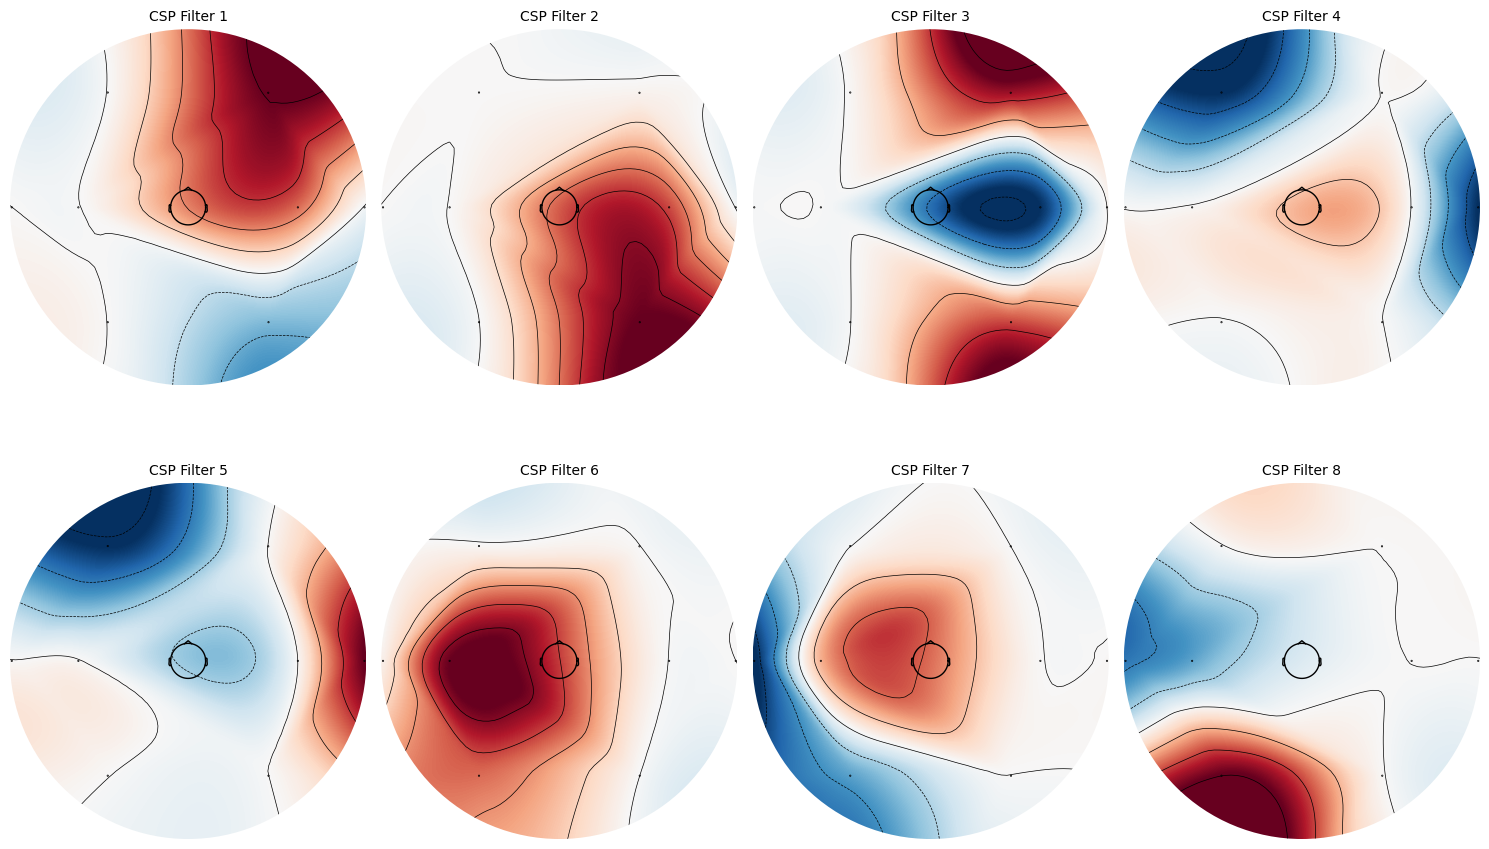

In [93]:
from mne.viz import plot_topomap

chans = data['chans']
# Plot topomap
fig, axes = plt.subplots(2, 4, figsize=(15, 10))
for i in range(w.shape[1]):
    ax = axes[i // 4, i % 4]
    plot_topomap(w[:, i], chans, axes=ax, show=False)
    ax.set_title(f'CSP Filter {i+1}', fontsize=10)
plt.tight_layout()
plt.show()

## 13 Comparison of manual CSP and MNE CSP

Computing rank from data with rank=None
    Using tolerance 0.49 (2.2e-16 eps * 8 dim * 2.8e+14  max singular value)
    Estimated rank (data): 8
    data: rank 8 computed from 8 data channels with 0 projectors
Reducing data rank from 8 -> 8
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Manual CSP weights:
 [[ 0.812  0.032  0.58   0.003  0.002  0.002  0.     0.003]
 [ 0.468  0.557 -0.686 -0.006  0.001 -0.002  0.006  0.001]
 [-0.348  0.83   0.439  0.002 -0.001 -0.    -0.001  0.009]
 [-0.008 -0.005  0.    -0.703  0.701 -0.     0.008 -0.001]
 [ 0.004  0.004  0.015 -0.711 -0.713  0.021 -0.002 -0.007]
 [-0.004  0.004 -0.005  0.01   0.006  0.867  0.321 -0.39 ]
 [-0.001 -0.002 -0.002 -0.005  0.002  0.493 -0.439  0.749]
 [ 0.    -0.002 -0.006 -0.006  0.004  0.072 -0.839 -0.536]]

MNE CSP weights:
 [[ 0.809  0.003  0.001  0.026  0.584  0.002  0.003  0.002]
 [ 0.466  0.     0.007  0.576 -0.672 -0.002 -0.005  0.001]
 [-0.357  0.009 -0.    

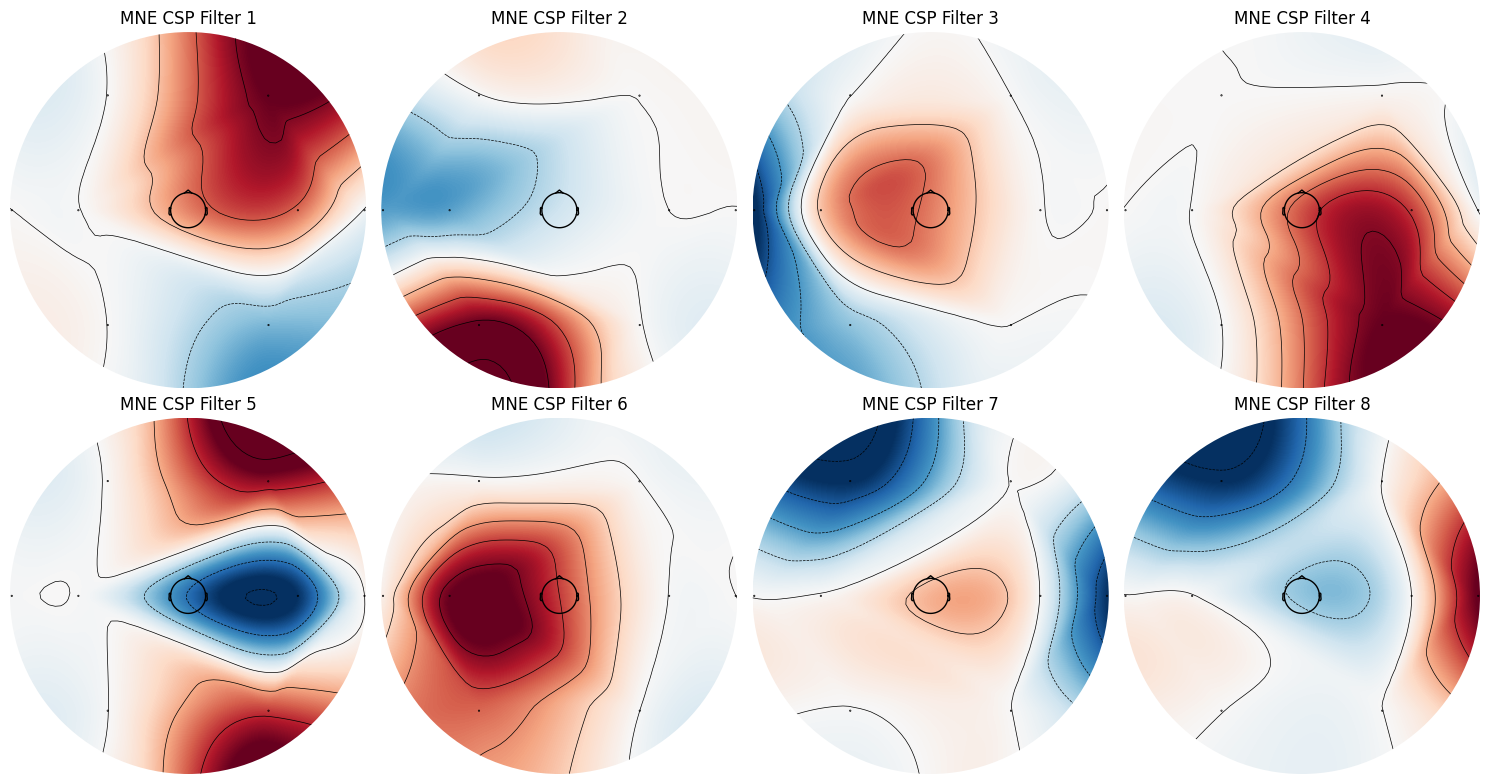

In [94]:

import numpy as np
import matplotlib.pyplot as plt
import mne.decoding
from mne.viz import plot_topomap

# check the shape of train_data and transpose if necessary
X = np.asarray(train_data)
if X.shape[1] != 8:
    X = X.transpose(0, 2, 1)

# MNE CSP 
csp = mne.decoding.CSP(n_components=8, reg=None, log=None, norm_trace=True)
csp.fit(train_data, train_labels)

w_mne = csp.filters_.T.copy()
for i in range(w_mne.shape[1]):
    w_mne[:, i] /= np.linalg.norm(w_mne[:, i])
    if w_mne[0, i] != 0:
        w_mne[:, i] *= np.sign(w_mne[0, i])

# print weights
print("Manual CSP weights:\n", np.round(w, 3))
print("\nMNE CSP weights:\n", np.round(w_mne, 3))

# Plot the 8 MNE topographies
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for i in range(8):
    ax = axes[i // 4, i % 4]
    plot_topomap(w_mne[:, i], data['chans'], axes=ax, show=False)
    ax.set_title(f"MNE CSP Filter {i+1}")

plt.tight_layout()
plt.show()


## 14 Selection of the 6 CSP filters

In [95]:
w_selected = np.hstack((w[:, :3], w[:, -3:]))

print("Selected CSP weights shape:", w_selected.shape)
print("Selected eigenvalues:", np.concatenate((eigvals[:3], eigvals[-3:])))
print("Selected CSP weights:\n", w_selected)

Selected CSP weights shape: (8, 6)
Selected eigenvalues: [0.80512436 0.80123335 0.79930209 0.20515786 0.20000426 0.19920165]
Selected CSP weights:
 [[ 8.12402458e-01  3.19032167e-02  5.79597297e-01  1.86101451e-03
   1.53770425e-04  3.00200644e-03]
 [ 4.68068000e-01  5.57023704e-01 -6.86464899e-01 -2.34836794e-03
   6.38108057e-03  8.88278715e-04]
 [-3.47591006e-01  8.29841827e-01  4.38807223e-01 -9.25978013e-05
  -1.15757345e-03  8.71623993e-03]
 [-7.86803177e-03 -4.75265457e-03  2.02036968e-04 -1.23553240e-04
   7.65041511e-03 -1.28623334e-03]
 [ 4.26958384e-03  4.27062098e-03  1.46975257e-02  2.09563317e-02
  -2.43188755e-03 -7.27948543e-03]
 [-3.63250473e-03  4.47215909e-03 -5.25645847e-03  8.66584766e-01
   3.21333555e-01 -3.90101137e-01]
 [-1.29586168e-03 -1.61813056e-03 -1.55470769e-03  4.93412919e-01
  -4.39039040e-01  7.48874956e-01]
 [ 2.78754215e-04 -2.42403361e-03 -5.91877042e-03  7.15986361e-02
  -8.38977320e-01 -5.35599648e-01]]


## 15 Feature extraction using CSP variances

In [96]:
def extract_csp_features(eeg_data, w_selected):
    features = []

    for event in eeg_data:
        # Project EEG data onto the 6 CSP filters
        projected = w_selected.T @ event

        # Calculate variance of each projected channel
        variances = np.diag(np.cov(projected))

        features.append(variances)

    return np.array(features)


# Extract features for training and testing
train_features = extract_csp_features(train_data, w_selected)
test_features = extract_csp_features(test_data, w_selected)

print("Training features shape:", train_features.shape)
print("Testing features shape:", test_features.shape)
print("First event features:", train_features[0])

Training features shape: (30, 6)
Testing features shape: (10, 6)
First event features: [1.00937325 1.00692239 1.04051767 4.12842717 4.18553151 4.44845195]


## Q1 plot

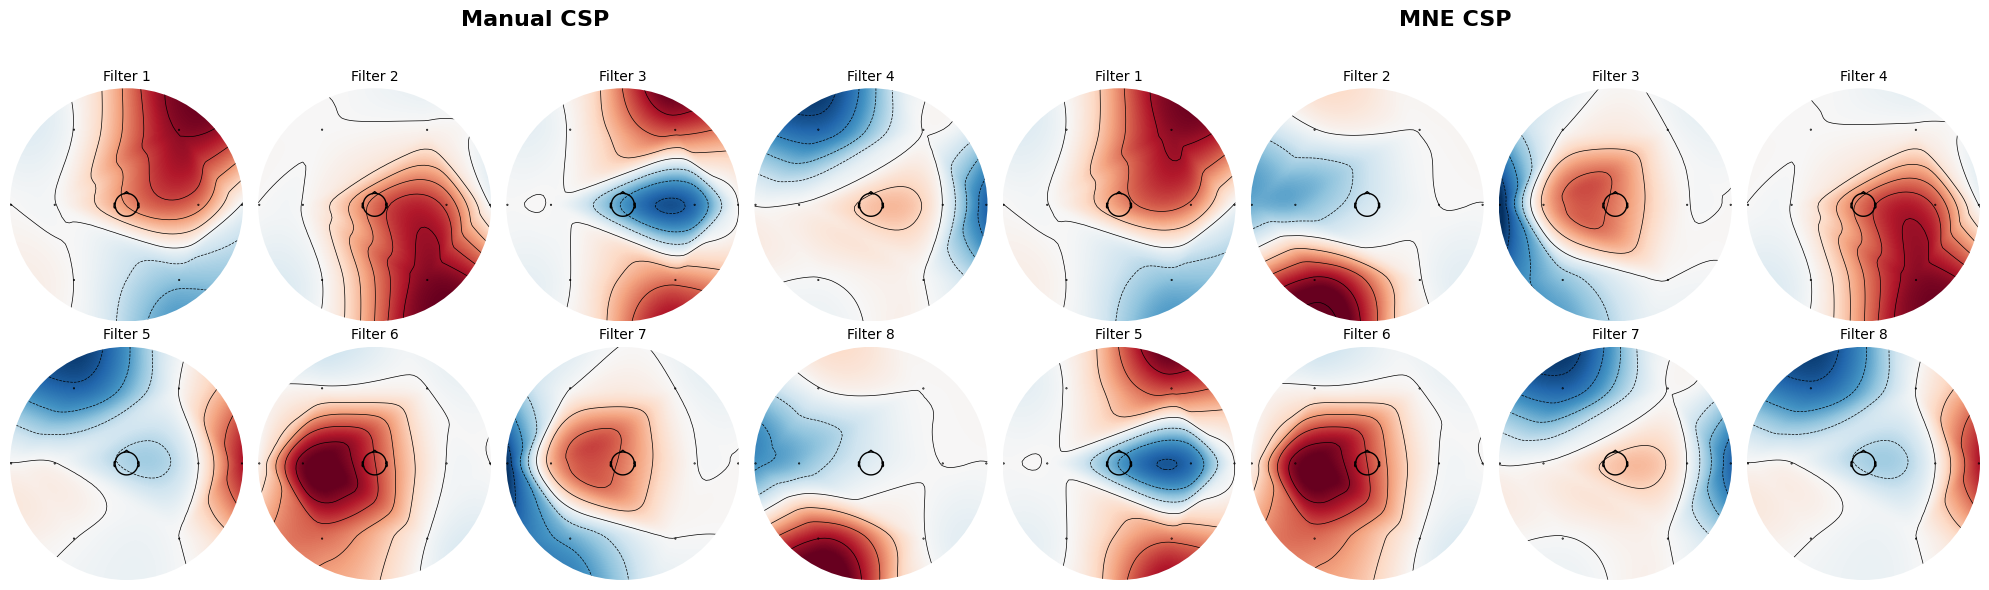

In [101]:

import numpy as np
import matplotlib.pyplot as plt
from mne.viz import plot_topomap

chans = data['chans']

# Use the same color scale for both methods
vmax = max(np.abs(w).max(), np.abs(w_mne).max())

fig, axes = plt.subplots(2, 8, figsize=(20, 6))


for i in range(8):
    row = i // 4
    col = i % 4

    # Manual CSP (left)
    plot_topomap(w[:, i], chans, axes=axes[row, col],
                 vlim=(-vmax, vmax), show=False)
    axes[row, col].set_title(f"Filter {i+1}", fontsize=10)

    # MNE CSP (right)
    plot_topomap(w_mne[:, i], chans, axes=axes[row, col + 4],
                 vlim=(-vmax, vmax), show=False)
    axes[row, col + 4].set_title(f"Filter {i+1}", fontsize=10)

fig.text(0.27, 0.98, "Manual CSP", ha="center",
         fontsize=16, fontweight="bold")
fig.text(0.73, 0.98, "MNE CSP", ha="center",
         fontsize=16, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()
